# Multi-epoch fitting

In monitoring (reverberation-mapping) campaigns the broad lines and continuum vary,
while the narrow lines stay constant. `fa.fit_epochs` fits all epochs **together**:

* parameters matching `shared` (by default all narrow-line parameters) have one value
  for all epochs;
* everything else is free per epoch;
* with `intercalibrate=True`, each epoch gets a flux scale factor, which the constant
  narrow lines determine. This corrects calibration differences between epochs.

Here we make 12 **simulated** epochs from a real SDSS quasar: the broad lines and
continuum vary, every epoch gets a random calibration error of up to ±15%, and noise is
added. We know the truth, so we can check the result.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import fantasy_agn as fa

spec = fa.read("spec-1059-52618-0453.fits").to_rest_frame()
truth = fa.fit(spec, fa.presets.hbeta(), verbose=False)

rng = np.random.default_rng(42)
spectra, true_scale, true_hb = [], [], []
for k in range(12):
    m = truth.model.copy()
    var = 1 + 0.35 * np.sin(2 * np.pi * k / 9)
    for name in ["broad.Hb.flux", "broad.Hg.flux", "broad2.Hb.flux", "broad2.Hg.flux"]:
        m.params[name].value *= var
    m.params["continuum.amp"].value *= 1 + 0.2 * np.sin(2 * np.pi * (k - 1.5) / 9)
    scale = 1.0 if k == 0 else rng.uniform(0.85, 1.15)
    flux = scale * m.evaluate(spec.wave, spec.context) + rng.normal(0, spec.err)
    spectra.append(spec.copy(flux=flux, mjd=55000 + 15 * k, name=f"epoch {k}"))
    true_scale.append(scale)
    full = m.params.full_values()
    true_hb.append(full[m.params.index("broad.Hb.flux")] + full[m.params.index("broad2.Hb.flux")])

In [2]:
res = fa.fit_epochs(spectra, fa.presets.hbeta(), shared=["narrow.*"])

Joint fit of 12 epochs: chi2 = 14878.0, dof = 14815, reduced chi2 = 1.004, 12 evaluations, 23.0 s
  shared: narrow.*
  errors scaled by sqrt(reduced chi2) = 1.00


The flux scale factors are recovered (the first epoch is the reference):

In [3]:
res.scales.assign(true=true_scale).round(3)

,epoch,mjd,scale,error,true
0,0,55000,1.000,0.000,1.000
1,1,55015,1.046,0.019,1.045
2,2,55030,1.030,0.019,1.063
3,3,55045,0.996,0.019,0.990
4,4,55060,1.127,0.020,1.138
5,5,55075,0.933,0.018,0.949
6,6,55090,0.938,0.018,0.930
7,7,55105,0.862,0.018,0.914
8,8,55120,1.100,0.020,1.091
9,9,55135,0.869,0.018,0.868


`light_curve()` gives, per epoch, the total broad flux and FWHM of every broad line
(all broad components together) and the continuum, with errors:

In [4]:
lc = res.light_curve()
lc.round(3)

,epoch,mjd,name,HeII4686_flux,HeII4686_flux_err,HeII4686_fwhm,HeII4686_fwhm_err,Hg_flux,Hg_flux_err,Hg_fwhm,Hg_fwhm_err,Hb_flux,Hb_flux_err,Hb_fwhm,Hb_fwhm_err,cont5100,cont5100_err
0,0,55000,epoch 0,234.876,39.943,4215.407,557.690,1724.103,279.888,4500.342,243.133,4191.502,150.816,4492.801,63.390,25.417,0.320
1,1,55015,epoch 1,692.216,177.283,7374.792,537.606,2384.351,318.686,4742.353,246.598,5187.859,208.126,4561.238,61.442,28.325,0.678
2,2,55030,epoch 2,864.011,123.438,7734.551,434.318,2883.890,244.024,4982.949,162.091,5749.203,170.630,4526.628,45.971,34.180,0.683
3,3,55045,epoch 3,850.692,148.879,8763.851,673.776,2452.868,250.411,4855.743,200.891,5361.790,177.053,4587.602,51.187,36.031,0.748
4,4,55060,epoch 4,901.141,66.288,7332.562,315.749,2314.989,199.129,4800.238,144.588,4787.028,147.502,4506.587,49.439,37.340,0.711
5,5,55075,epoch 5,811.716,86.157,7637.686,521.221,1382.192,238.580,4483.275,259.764,3720.452,148.404,4527.808,70.997,35.593,0.758
6,6,55090,epoch 6,684.419,161.198,6861.820,495.790,1251.480,241.833,4509.984,320.980,2867.804,137.734,4365.654,97.176,30.739,0.646
7,7,55105,epoch 7,867.752,74.449,7155.370,387.794,1269.057,192.285,4723.170,254.461,2876.833,133.155,4462.563,95.427,28.766,0.627
8,8,55120,epoch 8,593.394,94.801,8154.645,644.034,1197.445,141.148,4506.117,183.024,2996.164,99.843,4490.550,65.054,25.015,0.485
9,9,55135,epoch 9,857.022,120.898,7754.269,573.856,1736.539,259.367,4614.039,247.278,4037.733,177.366,4532.481,73.551,25.533,0.606


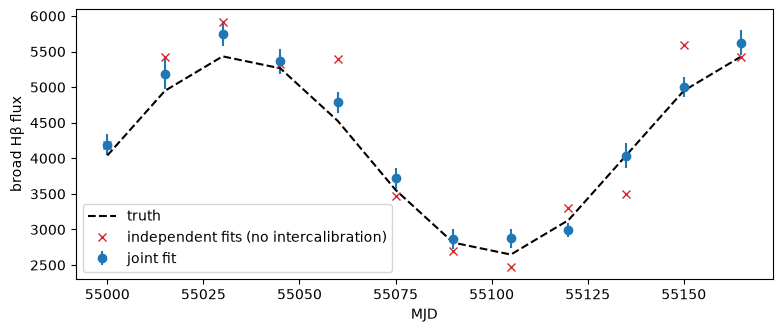

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(lc.mjd, lc.Hb_flux, lc.Hb_flux_err, fmt="o", label="joint fit")
ax.plot(lc.mjd, true_hb, "k--", label="truth")
independent = [fa.fit(s, fa.presets.hbeta(), verbose=False).measure("Hb", ["broad", "broad2"])["flux"]
               for s in spectra]
ax.plot(lc.mjd, independent, "x", color="C3", label="independent fits (no intercalibration)")
ax.set_xlabel("MJD"); ax.set_ylabel("broad Hβ flux"); ax.legend();

The independent fits follow the calibration errors of each epoch. The joint fit
removes them through the shared narrow lines, so its broad-line light curve follows
the truth within its error bars.

Shared parameters and any epoch can be inspected like a single-epoch result:

In [6]:
res.shared.round(3)

,parameter,value,error,unit
0,narrow.Hg.flux,15.004,1.810,flux*A
1,narrow.[OIII]4363.flux,12.229,1.608,flux*A
2,narrow.Hb.flux,52.185,1.971,flux*A
3,narrow.[OIII]4959.flux,155.956,2.100,flux*A
4,narrow.[OIII]5007.flux,464.749,6.259,flux*A
5,narrow.shift,67.786,0.549,km/s
6,narrow.fwhm,267.202,1.410,km/s


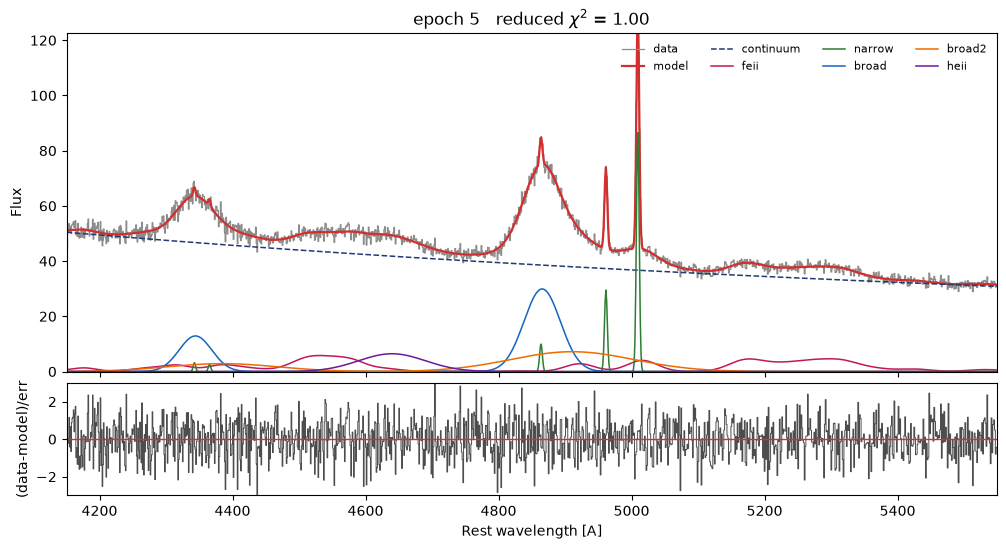

In [7]:
res.plot(epoch=5);